In [2]:
import os
import rasterio
import numpy as np
import matplotlib.pyplot as plt

from rasterio.vrt import WarpedVRT
from rasterio.enums import Resampling
from rasterio.merge import merge
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from rasterio.vrt import WarpedVRT
from osgeo import gdal

In [3]:
folder = r"mapbiomas/"
raster_files = [
    os.path.join(folder, "MapBiomas_C11_LegalAmazon_2024-0000000000-0000000000.tif"),
    os.path.join(folder, "MapBiomas_C11_LegalAmazon_2024-0000000000-0000065536.tif"),
    os.path.join(folder, "MapBiomas_C11_LegalAmazon_2024-0000065536-0000000000.tif"),
    os.path.join(folder, "MapBiomas_C11_LegalAmazon_2024-0000065536-0000065536.tif")
]

# Check files exist
for f in raster_files:
    if not os.path.exists(f):
        raise FileNotFoundError(f"File not found: {f}")


In [4]:
classes = {
    3: ("Forest formation", "#1f8d49"),
    4: ("Savanna formation", "#7dc975"),
    5: ("Mangrove", "#04381d"),
    6: ("Floodable forest", "#026975"),
    49: ("Wooded sandbank vegetation", "#02d659"),
    11: ("Wetland", "#519799"),
    12: ("Grassland", "#d6bc74"),
    32: ("Hypersaline tidal flat", "#fc8114"),
    29: ("Rocky outcrop", "#ffaa5f"),
    50: ("Herbaceous sandbank vegetation", "#ad5100"),
    15: ("Pasture", "#edde8e"),
    18: ("Agriculture", "#e974ed"),
    19: ("Temporary crops", "#c27ba0"),
    39: ("Soybean", "#f5b3c8"),
    20: ("Sugar cane", "#db7093"),
    40: ("Rice", "#c71585"),
    62: ("Cotton", "#ff69b4"),
    41: ("Other temporary crops", "#f54ca9"),
    36: ("Perennial crops", "#d082de"),
    46: ("Coffee", "#d68fe2"),
    47: ("Citrus", "#9932cc"),
    35: ("Oil palm", "#9065d0"),
    48: ("Other perennial crops", "#a789d7"),
    9: ("Forest plantation", "#7a5900"),
    21: ("Mosaic of uses", "#ffefc3"),
    22: ("Non-vegetated area", "#d4271e"),
    23: ("Beach and dune", "#ffa07a"),
    24: ("Urban infrastructure", "#d4271e"),
    30: ("Mining", "#9c0027"),
    25: ("Other non-vegetated area", "#db4d4f"),
    33: ("River, lake and ocean", "#2532e4"),
    31: ("Aquaculture", "#091077"),
    26: ("Other", "#ffffff"),
    27: ("Not observed", "#ffffff"),
    80: ("Natural non-forest", "#b8af4f"),
    81: ("Aquatic", "#6e8bc7"),
    82: ("Other non-forest", "#c7d79e"),
    83: ("Other", "#ffccaa"),
    84: ("Salt marsh (beta)", "#81dbbf"),
}


In [5]:
sources = [rasterio.open(f) for f in raster_files]
# Check that all tiles have compatible grids.
for src in sources:
    print(src.name, src.width, src.height, src.crs)

mapbiomas/MapBiomas_C11_LegalAmazon_2024-0000000000-0000000000.tif 65536 65536 EPSG:4326
mapbiomas/MapBiomas_C11_LegalAmazon_2024-0000000000-0000065536.tif 45736 65536 EPSG:4326
mapbiomas/MapBiomas_C11_LegalAmazon_2024-0000065536-0000000000.tif 65536 20965 EPSG:4326
mapbiomas/MapBiomas_C11_LegalAmazon_2024-0000065536-0000065536.tif 45736 20965 EPSG:4326


In [6]:
vrt_path = os.path.join(folder, "MapBiomas_LegalAmazon_2024.vrt")
vrt = gdal.BuildVRT(vrt_path, raster_files)
if vrt is None:
    raise RuntimeError("Could not create VRT. Check input files and their projections.")
vrt.FlushCache()
vrt = None
if not os.path.exists(vrt_path):
    raise FileNotFoundError("The VRT file was not created.")

c:\Users\ADM\miniconda3\envs\geo_env\Lib\site-packages\osgeo\gdal.py:606: FutureWarning: Neither gdal.UseExceptions() nor gdal.DontUseExceptions() has been explicitly called. In GDAL 4.0, exceptions will be enabled by default.
  warnings.warn(


In [7]:
with rasterio.open(vrt_path) as src:
    print("Mosaic dimensions:", src.width, src.height)
    print("CRS:", src.crs)
    max_dimension = 3000
    scale = max(src.width / max_dimension, src.height / max_dimension, 1)
    out_width = max(1, int(src.width / scale))
    out_height = max(1, int(src.height / scale))
    landcover = src.read(1, out_shape=(out_height, out_width), resampling=Resampling.nearest)
    nodata = src.nodata

# Close original files
for src in sources:
    src.close()

valid = np.isfinite(landcover)

if nodata is not None:
    valid &= landcover != nodata

present_classes = np.unique(landcover[valid])
present_classes = sorted(int(c) for c in present_classes if c != 0 and int(c) in classes)
print("Classes present:", present_classes)

colors = [classes[c][1] for c in present_classes]
cmap = ListedColormap(colors)
plot_data = np.full(landcover.shape, np.nan)
for i, class_id in enumerate(present_classes):
    plot_data[landcover == class_id] = i

Mosaic dimensions: 111272 86501
CRS: EPSG:4326


Classes present: [3, 4, 5, 6, 9, 11, 12, 15, 20, 21, 23, 24, 25, 29, 30, 31, 32, 33, 35, 39, 40, 41, 62]


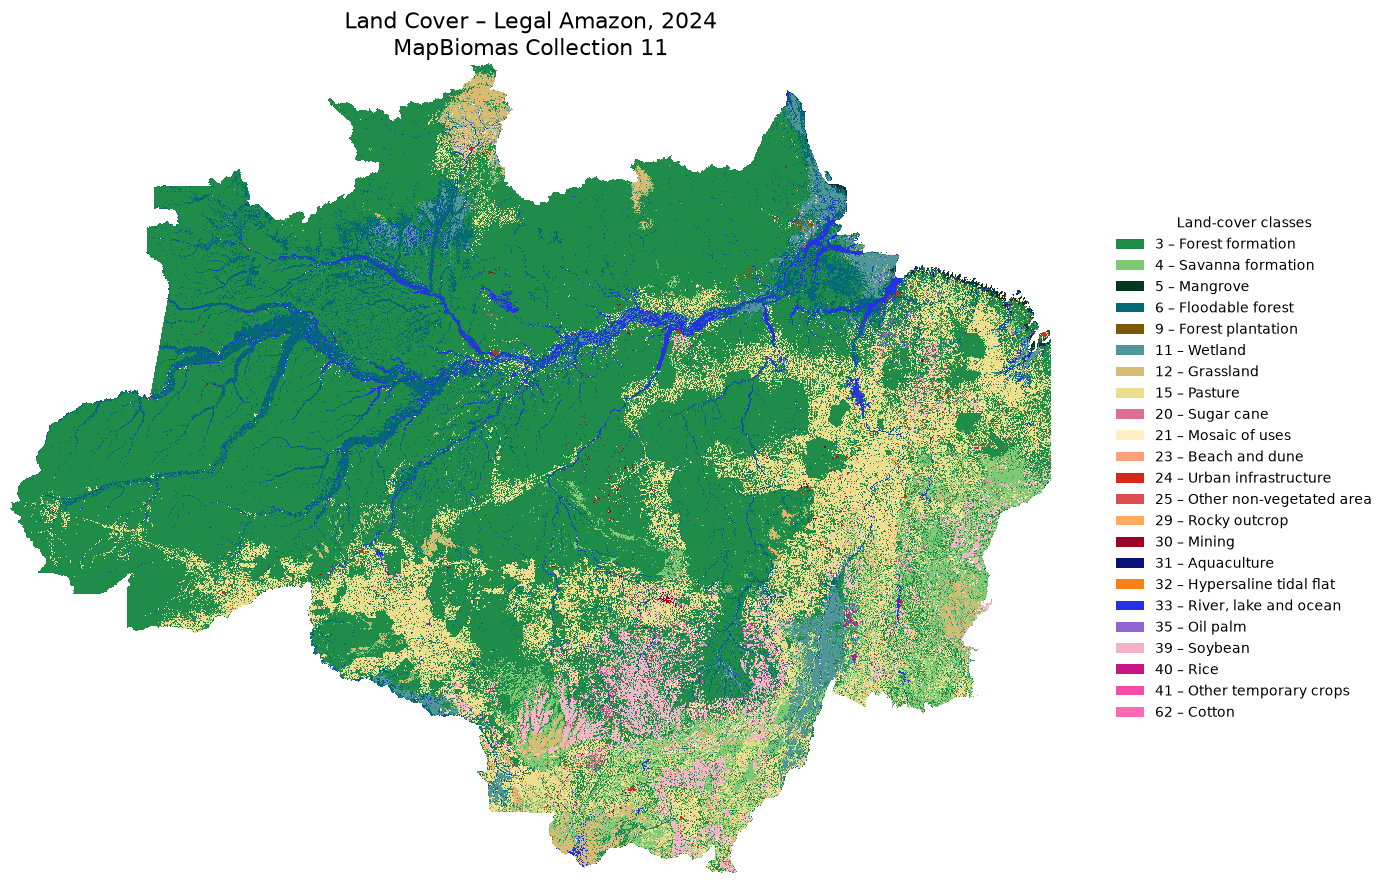

In [8]:
fig, ax = plt.subplots(figsize=(14, 12))
ax.imshow(plot_data, cmap=cmap, vmin=-0.5, vmax=len(colors) - 0.5, interpolation="nearest")
ax.set_title("Land Cover – Legal Amazon, 2024\nMapBiomas Collection 11", fontsize=16)
ax.axis("off")
legend_elements = [Patch(facecolor=classes[c][1], label=f"{c} – {classes[c][0]}") for c in present_classes]
ax.legend(handles=legend_elements, loc="center left", bbox_to_anchor=(1.05, 0.5), fontsize=10, title="Land-cover classes", frameon=False)
plt.tight_layout()
plt.savefig(os.path.join(folder, "MapBiomas_LegalAmazon_2024.png"), dpi=300, bbox_inches="tight", facecolor="white")
plt.show()

In [9]:
class_names = {
    3: "Forest formation",
    4: "Savanna formation",
    5: "Mangrove",
    6: "Floodable forest",
    49: "Wooded sandbank vegetation",
    11: "Wetland",
    12: "Grassland",
    32: "Hypersaline tidal flat",
    29: "Rocky outcrop",
    50: "Herbaceous sandbank vegetation",
    15: "Pasture",
    18: "Agriculture",
    19: "Temporary crops",
    39: "Soybean",
    20: "Sugar cane",
    40: "Rice",
    62: "Cotton",
    41: "Other temporary crops",
    36: "Perennial crops",
    46: "Coffee",
    47: "Citrus",
    35: "Oil palm",
    48: "Other perennial crops",
    9: "Forest plantation",
    21: "Mosaic of uses",
    22: "Non-vegetated area",
    23: "Beach and dune",
    24: "Urban infrastructure",
    30: "Mining",
    25: "Other non-vegetated area",
    33: "River, lake and ocean",
    31: "Aquaculture",
    26: "Other",
    27: "Not observed",
    80: "Natural non-forest",
    81: "Aquatic",
    82: "Other non-forest",
    83: "Other",
    84: "Salt marsh (beta)"
}

In [ ]:
from collections import Counter
import pandas as pd

class_counts = Counter()
total_pixels = 0

for file in raster_files:
    with rasterio.open(file) as src:
        print("Processing:", os.path.basename(file))
        for _, window in src.block_windows(1):
            block = src.read(1, window=window)
            # Exclude NoData and background (0)
            valid = block != 0
            if src.nodata is not None:
                valid &= block != src.nodata
            values, counts = np.unique(block[valid], return_counts=True)
            for value, count in zip(values, counts):
                class_counts[int(value)] += int(count)
            total_pixels += int(valid.sum())

results = []
for class_id, count in sorted(class_counts.items()):

    results.append({
        "class_id": class_id,
        "class_name": class_names.get(class_id, "Unknown"),
        "pixel_count": count,
        "area_km2": count * 0.0009,
        "percentage": count / total_pixels * 100
    })

df_classes = pd.DataFrame(results)
df_classes = df_classes.sort_values("percentage", ascending=False).reset_index(drop=True)

print(df_classes.to_string(index=False))
print("\nTotal valid pixels:", total_pixels)
print("Total area (km²):", total_pixels * 0.0009)
print("Sum of percentages:", df_classes["percentage"].sum())

df_classes.to_csv(os.path.join(folder, "MapBiomas_LegalAmazon_2024_class_percentages.csv"), index=False)

Processing: MapBiomas_C11_LegalAmazon_2024-0000000000-0000000000.tif
Processing: MapBiomas_C11_LegalAmazon_2024-0000000000-0000065536.tif
Processing: MapBiomas_C11_LegalAmazon_2024-0000065536-0000000000.tif
Processing: MapBiomas_C11_LegalAmazon_2024-0000065536-0000065536.tif
 class_id                     class_name  pixel_count     area_km2  percentage
        3               Forest formation   3433897695 3090507.9255   60.672088
       15                        Pasture    775836467  698252.8203   13.707927
        6               Floodable forest    425875350  383287.8150    7.524612
        4              Savanna formation    292598902  263339.0118    5.169806
       39                        Soybean    167473442  150726.0978    2.959018
       11                        Wetland    163299367  146969.4303    2.885268
       33          River, lake and ocean    131616058  118454.4522    2.325469
       12                      Grassland    117545129  105790.6161    2.076855
       21    